In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
input_folder = r"C:\academics\codes\DSIP\OPE\input"
output_folder = r"C:\academics\codes\DSIP\OPE\output"
os.makedirs(output_folder, exist_ok=True)
print("Folders ready")

Folders ready


In [3]:
image_names = ["ope5_image1.png", "ope5_image2.png", "ope5_image3.png", "ope5_image4.png"]
images = []

for i, name in enumerate(image_names, 1):
    img = cv2.imread(os.path.join(input_folder, name))
    if img is None:
        print("Image", i, "not found")
    else:
        print("Image", i, "loaded successfully")
    images.append(img)

Image 1 loaded successfully
Image 2 loaded successfully
Image 3 loaded successfully
Image 4 loaded successfully


In [4]:
gray_images = [cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) for img in images]
gray1, gray2, gray3, gray4 = gray_images

titles = ["Image 1 (Portrait)", "Image 2 (Knee X-ray)",
          "Image 3 (City skyline)", "Image 4 (Building)"]

for t, g in zip(titles, gray_images):
    print(f"{t:24s} size = {g.shape[1]} x {g.shape[0]}  dtype = {g.dtype}  "
          f"min = {g.min()}  max = {g.max()}  mean = {g.mean():.1f}")

Image 1 (Portrait)       size = 222 x 247  dtype = uint8  min = 0  max = 255  mean = 105.6
Image 2 (Knee X-ray)     size = 173 x 253  dtype = uint8  min = 0  max = 255  mean = 155.4
Image 3 (City skyline)   size = 602 x 301  dtype = uint8  min = 0  max = 255  mean = 156.1
Image 4 (Building)       size = 602 x 288  dtype = uint8  min = 38  max = 221  mean = 123.9


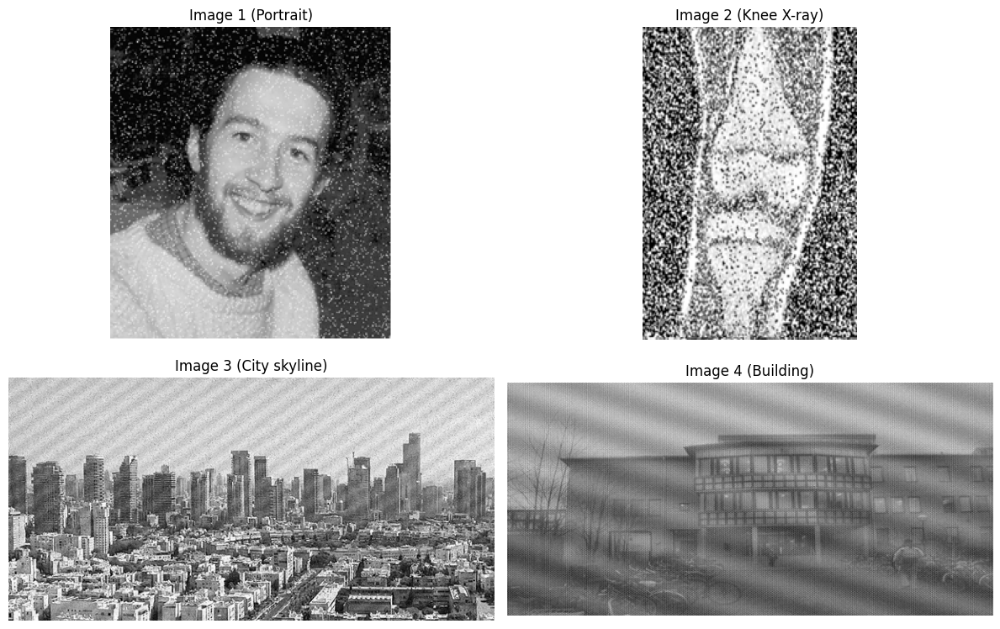

In [5]:
plt.figure(figsize=(12, 8))
for i, (g, t) in enumerate(zip(gray_images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(g, cmap="gray", vmin=0, vmax=255)
    plt.title(t)
    plt.axis("off")
plt.tight_layout()
plt.show()

## Step 1 - Identify the noise type
* Impulse (salt-and-pepper) noise -> spikes at gray level 0 and 255 in the histogram.
* Periodic noise -> isolated bright peaks in the Fourier spectrum.

findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


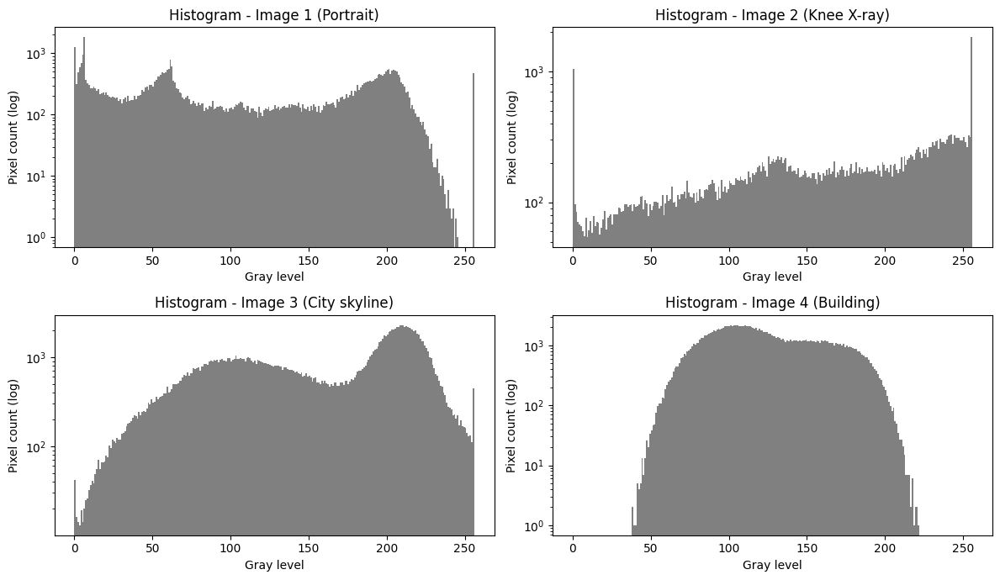

Image                     Near 0 (<=10)  Near 255 (>=245)  Outliers vs median
Image 1 (Portrait)               13.51%             0.86%               4.45%
Image 2 (Knee X-ray)              3.95%            11.12%              19.23%
Image 3 (City skyline)            0.14%             1.13%               4.14%
Image 4 (Building)                0.00%             0.00%               0.00%


In [ ]:
def impulse_fractions(img, tol=10):
    
    pepper = np.count_nonzero(img <= tol) / img.size
    salt = np.count_nonzero(img >= 255 - tol) / img.size
    return pepper, salt

def impulse_detect_fraction(img, T=50):
    d = np.abs(img.astype(np.int16) - cv2.medianBlur(img, 3).astype(np.int16))
    return float(np.mean(d > T))

plt.figure(figsize=(12, 7))
for i, (g, t) in enumerate(zip(gray_images, titles), 1):
    plt.subplot(2, 2, i)
    plt.hist(g.ravel(), bins=256, range=(0, 256), color="gray")
    plt.yscale("log")
    plt.title("Histogram - " + t)
    plt.xlabel("Gray level")
    plt.ylabel("Pixel count (log)")
plt.tight_layout()
plt.show()

print(f"{'Image':24s}{'Near 0 (<=10)':>15s}{'Near 255 (>=245)':>18s}{'Outliers vs median':>20s}")
for t, g in zip(titles, gray_images):
    p, s = impulse_fractions(g)
    print(f"{t:24s}{p*100:14.2f}%{s*100:17.2f}%{impulse_detect_fraction(g)*100:19.2f}%")

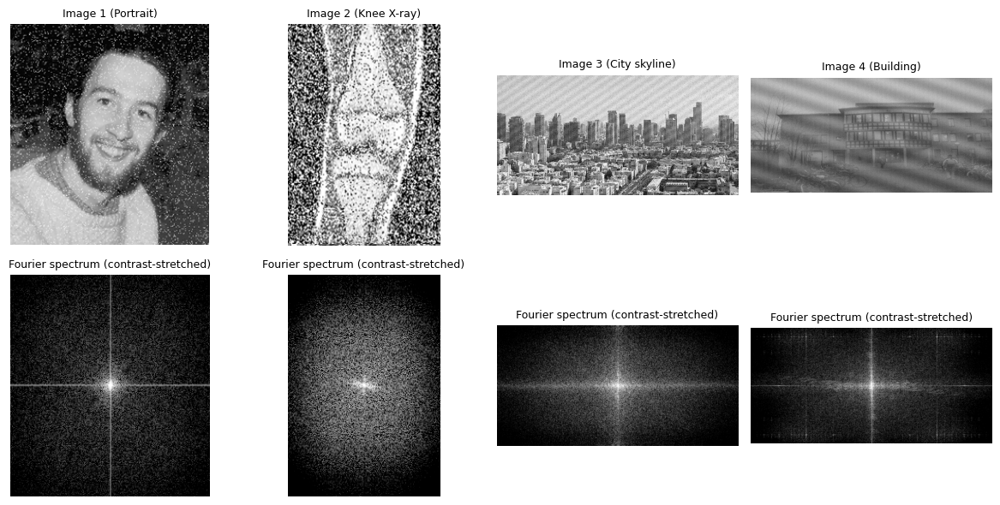

Image                     Spectral peak prominence
Image 1 (Portrait)                            2.59
Image 2 (Knee X-ray)                          1.65
Image 3 (City skyline)                        3.01
Image 4 (Building)                            5.55


In [7]:
def spectrum(img):
    F = np.fft.fftshift(np.fft.fft2(img.astype(np.float32)))
    return np.log1p(np.abs(F))

def peak_prominence(img, r_exclude=0.03):
    """Height of the strongest isolated spectral peak above its smooth surroundings
    (log scale). Large value -> periodic noise."""
    mag = spectrum(img)
    prom = mag - cv2.GaussianBlur(mag, (0, 0), 8)
    h, w = img.shape
    yy, xx = np.ogrid[:h, :w]
    rr = np.hypot((yy - h // 2) / h, (xx - w // 2) / w)
    return float(prom[rr > r_exclude].max())

plt.figure(figsize=(12, 6))
for i, (g, t) in enumerate(zip(gray_images, titles), 1):
    plt.subplot(2, 4, i)
    plt.imshow(g, cmap="gray", vmin=0, vmax=255)
    plt.title(t, fontsize=9)
    plt.axis("off")
    plt.subplot(2, 4, i + 4)
    sp = spectrum(g)
    plt.imshow(sp, cmap="gray", vmin=np.percentile(sp, 30), vmax=np.percentile(sp, 99.97))
    plt.title("Fourier spectrum (contrast-stretched)", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

print(f"{'Image':24s}{'Spectral peak prominence':>26s}")
for t, g in zip(titles, gray_images):
    print(f"{t:24s}{peak_prominence(g):26.2f}")

## Step 2 - Metrics and filter definitions

In [8]:
def mse(a, b):
    return float(np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2))

def psnr(ref, img):
    m = mse(ref, img)
    return 99.0 if m == 0 else 10 * np.log10(255.0 ** 2 / m)

def ssim(a, b):
    a = a.astype(np.float64)
    b = b.astype(np.float64)
    C1, C2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    g = lambda x: cv2.GaussianBlur(x, (11, 11), 1.5)
    mu_a, mu_b = g(a), g(b)
    var_a = g(a * a) - mu_a ** 2
    var_b = g(b * b) - mu_b ** 2
    cov = g(a * b) - mu_a * mu_b
    s = ((2 * mu_a * mu_b + C1) * (2 * cov + C2)) / ((mu_a ** 2 + mu_b ** 2 + C1) * (var_a + var_b + C2))
    return float(s.mean())

def epi(ref, img):
    """Edge Preservation Index: correlation of Laplacian (edge) maps with the clean reference."""
    lr = cv2.Laplacian(ref.astype(np.float32), cv2.CV_32F)
    lf = cv2.Laplacian(img.astype(np.float32), cv2.CV_32F)
    lr, lf = lr - lr.mean(), lf - lf.mean()
    return float((lr * lf).sum() / np.sqrt((lr ** 2).sum() * (lf ** 2).sum()))

def noise_sigma(img):
    """Immerkaer fast estimate of the noise standard deviation (no reference needed)."""
    M = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)
    h, w = img.shape
    r = cv2.filter2D(img.astype(np.float32), -1, M, borderType=cv2.BORDER_REFLECT)[1:-1, 1:-1]
    return float(np.abs(r).sum() * np.sqrt(0.5 * np.pi) / (6.0 * (w - 2) * (h - 2)))

def mean_gradient(img):
    gx = cv2.Sobel(img, cv2.CV_32F, 1, 0)
    gy = cv2.Sobel(img, cv2.CV_32F, 0, 1)
    return float(np.mean(np.hypot(gx, gy)))

def impulse_percent(img, T=50):
    """Percentage of pixels that are outliers w.r.t. their 3x3 median (|pixel - median| > T)."""
    d = np.abs(img.astype(np.int16) - cv2.medianBlur(img, 3).astype(np.int16))
    return 100.0 * float(np.mean(d > T))

print("Metric functions ready")

Metric functions ready


In [9]:
def median_filter(img, k):
    return cv2.medianBlur(img, k)

def mean_filter(img, k):
    return cv2.blur(img, (k, k))

def min_filter(img, k):
    return cv2.erode(img, np.ones((k, k), np.uint8))

def max_filter(img, k):
    return cv2.dilate(img, np.ones((k, k), np.uint8))

def midpoint_filter(img, k):
    return ((min_filter(img, k).astype(np.uint16) + max_filter(img, k)) // 2).astype(np.uint8)

def alpha_trimmed_mean(img, k=5, d=6):
    """Sort the k*k window, discard the d/2 lowest and d/2 highest values, average the rest."""
    p = np.pad(img, k // 2, mode="reflect")
    win = np.lib.stride_tricks.sliding_window_view(p, (k, k)).reshape(img.shape[0], img.shape[1], k * k)
    win = np.sort(win, axis=2)
    return np.clip(win[:, :, d // 2: k * k - d // 2].mean(axis=2), 0, 255).astype(np.uint8)

def adaptive_median(img, s_max=7, tol=0):
    """Adaptive median filter. `tol` widens the 'is impulse' test: a pixel counts as an impulse
    when it lies within `tol` levels of the window min/max (needed for resampled images)."""
    out = img.copy()
    done = np.zeros(img.shape, bool)
    i16 = img.astype(np.int16)
    for k in range(3, s_max + 1, 2):
        kern = np.ones((k, k), np.uint8)
        zmin = cv2.erode(img, kern).astype(np.int16)
        zmax = cv2.dilate(img, kern).astype(np.int16)
        zmed = cv2.medianBlur(img, k)
        a1, a2 = zmed.astype(np.int16) - zmin, zmed.astype(np.int16) - zmax
        level_a = (a1 > 0) & (a2 < 0) & ~done
        keep = level_a & ((i16 - zmin) > tol) & ((zmax - i16) > tol)
        replace = level_a & ~keep
        out[keep] = img[keep]
        out[replace] = zmed[replace]
        done |= level_a
        if k == s_max:
            out[~done] = zmed[~done]
    return out

def switching_median(img, k=3, T=50):
    """Replace only pixels detected as impulses (|pixel - 3x3 median| > T); the rest stay untouched."""
    med3 = cv2.medianBlur(img, 3)
    noisy = np.abs(img.astype(np.int16) - med3.astype(np.int16)) > T
    out = img.copy()
    out[noisy] = cv2.medianBlur(img, k)[noisy]
    return out

def morph_open_close(img, k=3):
    kern = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
    return cv2.morphologyEx(cv2.morphologyEx(img, cv2.MORPH_OPEN, kern), cv2.MORPH_CLOSE, kern)

def show_grid(imgs, labels, rows, cols, figsize):
    plt.figure(figsize=figsize)
    for i, (im, lb) in enumerate(zip(imgs, labels), 1):
        plt.subplot(rows, cols, i)
        plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        plt.title(lb, fontsize=10)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

print("Filter functions ready")

Filter functions ready


## Step 3 - Median filtering with varying window size (impulse-noise images 1 and 2)

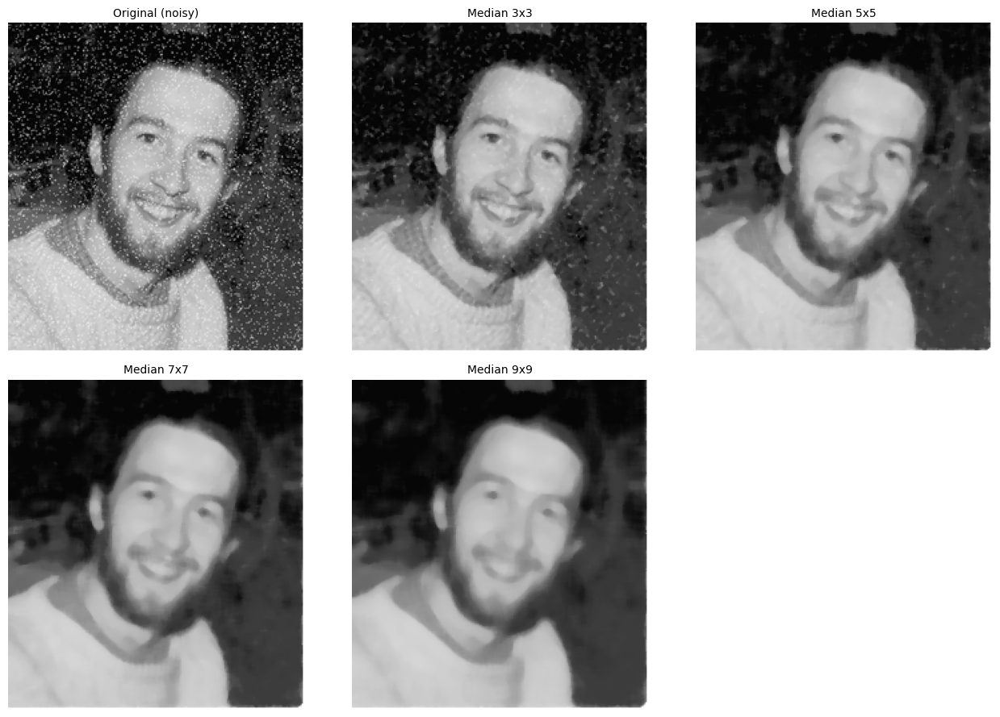

Filter              Impulse left (%)   Noise sigma  Mean gradient
Original                        4.45         12.01         114.87
Median 3x3                      0.05          2.84          60.48
Median 5x5                      0.00          1.29          42.14
Median 7x7                      0.00          0.87          35.83
Median 9x9                      0.00          0.68          32.26


In [10]:
sizes = [3, 5, 7, 9]
med1 = {k: median_filter(gray1, k) for k in sizes}

show_grid([gray1] + [med1[k] for k in sizes],
          ["Original (noisy)"] + [f"Median {k}x{k}" for k in sizes], 2, 3, (13, 9))

for k in sizes:
    cv2.imwrite(os.path.join(output_folder, f"image1_median_{k}x{k}.png"), med1[k])

print(f"{'Filter':18s}{'Impulse left (%)':>18s}{'Noise sigma':>14s}{'Mean gradient':>15s}")
print(f"{'Original':18s}{impulse_percent(gray1):18.2f}{noise_sigma(gray1):14.2f}{mean_gradient(gray1):15.2f}")
for k in sizes:
    print(f"{'Median ' + str(k) + 'x' + str(k):18s}{impulse_percent(med1[k]):18.2f}"
          f"{noise_sigma(med1[k]):14.2f}{mean_gradient(med1[k]):15.2f}")

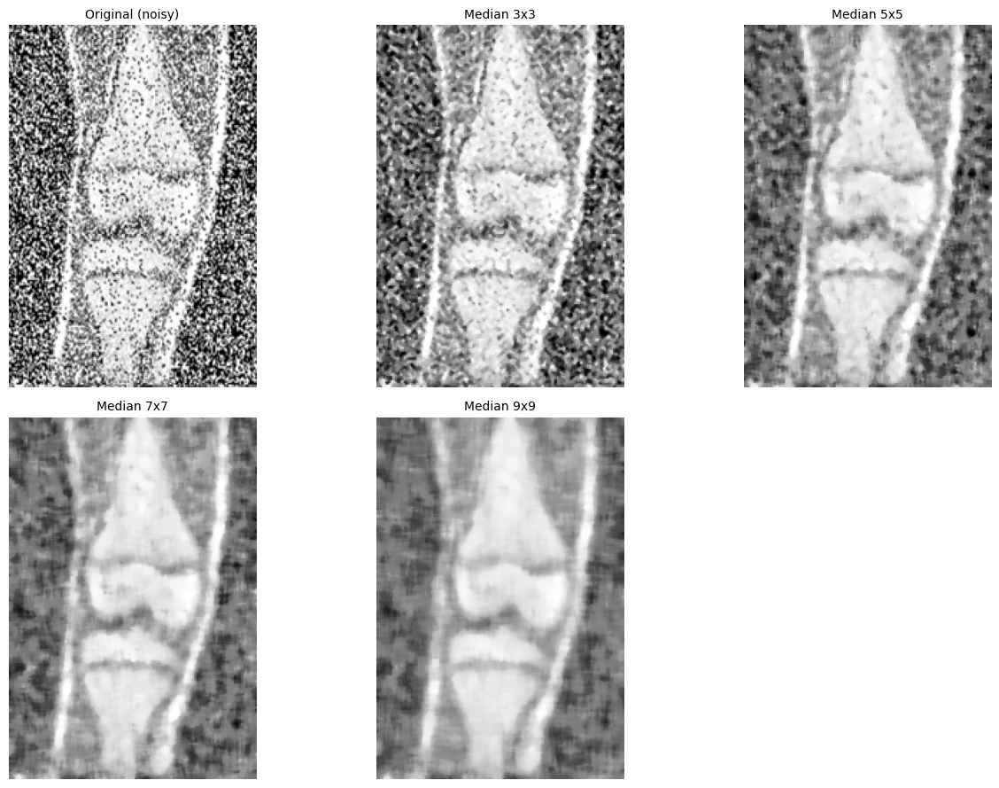

Filter              Impulse left (%)   Noise sigma  Mean gradient
Original                       19.23         19.36         317.04
Median 3x3                      1.50          9.45         188.49
Median 5x5                      0.06          4.18         107.09
Median 7x7                      0.00          2.45          74.71
Median 9x9                      0.00          1.66          57.16


In [11]:
med2 = {k: median_filter(gray2, k) for k in sizes}

show_grid([gray2] + [med2[k] for k in sizes],
          ["Original (noisy)"] + [f"Median {k}x{k}" for k in sizes], 2, 3, (13, 9))

for k in sizes:
    cv2.imwrite(os.path.join(output_folder, f"image2_median_{k}x{k}.png"), med2[k])

print(f"{'Filter':18s}{'Impulse left (%)':>18s}{'Noise sigma':>14s}{'Mean gradient':>15s}")
print(f"{'Original':18s}{impulse_percent(gray2):18.2f}{noise_sigma(gray2):14.2f}{mean_gradient(gray2):15.2f}")
for k in sizes:
    print(f"{'Median ' + str(k) + 'x' + str(k):18s}{impulse_percent(med2[k]):18.2f}"
          f"{noise_sigma(med2[k]):14.2f}{mean_gradient(med2[k]):15.2f}")

## Step 4 - Other non-linear filters on images 1 and 2

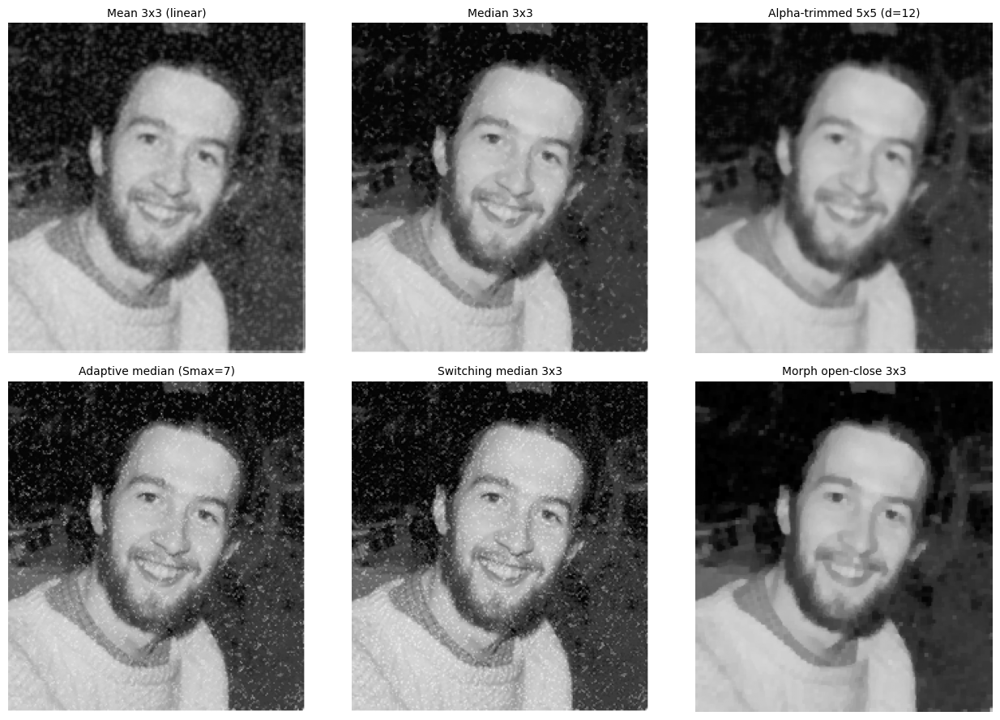

Filter                        Impulse left (%)   Noise sigma  Mean gradient
Mean 3x3 (linear)                         0.00          1.13          63.32
Median 3x3                                0.05          2.84          60.48
Alpha-trimmed 5x5 (d=12)                  0.00          0.55          37.99
Adaptive median (Smax=7)                  1.44          9.13          86.17
Switching median 3x3                      0.40          9.16          89.44
Morph open-close 3x3                      0.00          1.01          36.11


In [12]:
cands1 = {
    "Mean 3x3 (linear)": mean_filter(gray1, 3),
    "Median 3x3": med1[3],
    "Alpha-trimmed 5x5 (d=12)": alpha_trimmed_mean(gray1, 5, 12),
    "Adaptive median (Smax=7)": adaptive_median(gray1, 7),
    "Switching median 3x3": switching_median(gray1, 3),
    "Morph open-close 3x3": morph_open_close(gray1, 3),
}
show_grid(list(cands1.values()), list(cands1.keys()), 2, 3, (13, 9))

for name, im in cands1.items():
    cv2.imwrite(os.path.join(output_folder, "image1_" + name.split(" (")[0].replace(" ", "_") + ".png"), im)

print(f"{'Filter':28s}{'Impulse left (%)':>18s}{'Noise sigma':>14s}{'Mean gradient':>15s}")
for name, im in cands1.items():
    print(f"{name:28s}{impulse_percent(im):18.2f}{noise_sigma(im):14.2f}{mean_gradient(im):15.2f}")

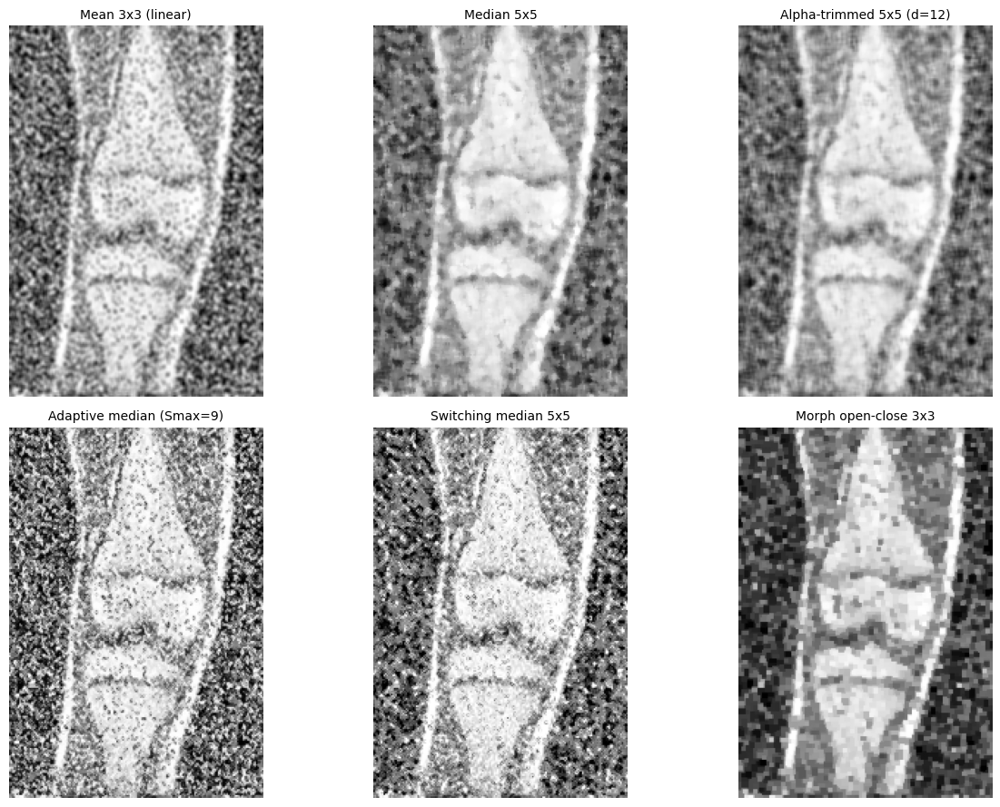

Filter                        Impulse left (%)   Noise sigma  Mean gradient
Mean 3x3 (linear)                         0.01          2.26         164.03
Median 5x5                                0.06          4.18         107.09
Alpha-trimmed 5x5 (d=12)                  0.00          1.28         101.40
Adaptive median (Smax=9)                 11.76         24.72         256.43
Switching median 5x5                      6.59         22.96         217.21
Morph open-close 3x3                      0.81          3.51         119.76


In [13]:
cands2 = {
    "Mean 3x3 (linear)": mean_filter(gray2, 3),
    "Median 5x5": med2[5],
    "Alpha-trimmed 5x5 (d=12)": alpha_trimmed_mean(gray2, 5, 12),
    "Adaptive median (Smax=9)": adaptive_median(gray2, 9),
    "Switching median 5x5": switching_median(gray2, 5),
    "Morph open-close 3x3": morph_open_close(gray2, 3),
}
show_grid(list(cands2.values()), list(cands2.keys()), 2, 3, (13, 9))

for name, im in cands2.items():
    cv2.imwrite(os.path.join(output_folder, "image2_" + name.split(" (")[0].replace(" ", "_") + ".png"), im)

print(f"{'Filter':28s}{'Impulse left (%)':>18s}{'Noise sigma':>14s}{'Mean gradient':>15s}")
for name, im in cands2.items():
    print(f"{name:28s}{impulse_percent(im):18.2f}{noise_sigma(im):14.2f}{mean_gradient(im):15.2f}")

## Step 5 - Periodic-noise images (3 and 4): non-linear filters and their limits
Images 3 and 4 contain fine grain *and* diagonal stripes. Rank filters can remove the grain,
but a stripe pattern is a large-scale, regular structure - a failure case for non-linear filtering.

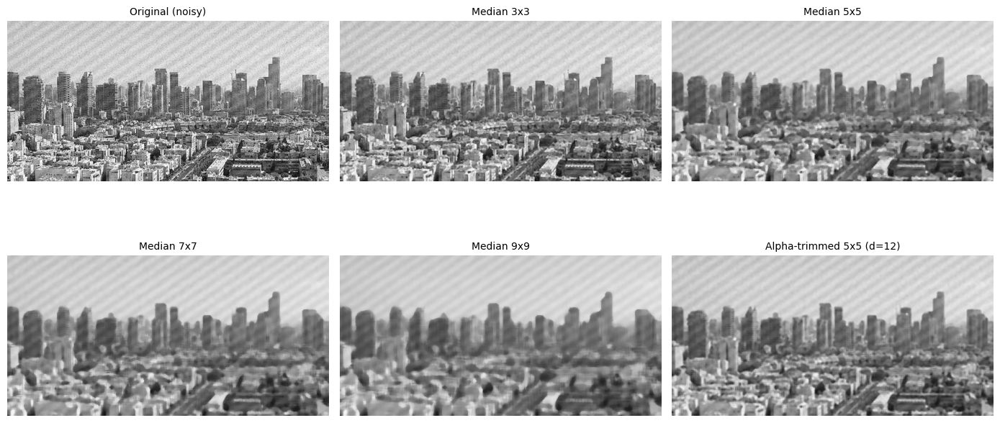

Image 3: spectral peak prominence (log units)
   Original (noisy)              3.01
   Median 3x3                    2.99
   Median 5x5                    2.97
   Median 7x7                    2.97
   Median 9x9                    2.97
   Alpha-trimmed 5x5 (d=12)      2.99


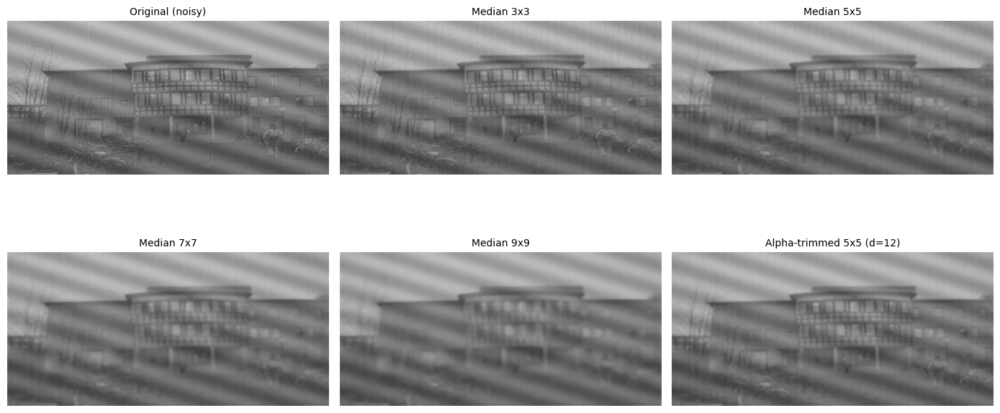

Image 4: spectral peak prominence (log units)
   Original (noisy)              5.55
   Median 3x3                    4.11
   Median 5x5                    3.92
   Median 7x7                    4.62
   Median 9x9                    4.69
   Alpha-trimmed 5x5 (d=12)      4.19


In [14]:
for idx, g in ((3, gray3), (4, gray4)):
    outs = [g] + [median_filter(g, k) for k in sizes] + [alpha_trimmed_mean(g, 5, 12)]
    labs = ["Original (noisy)"] + [f"Median {k}x{k}" for k in sizes] + ["Alpha-trimmed 5x5 (d=12)"]
    show_grid(outs, labs, 2, 3, (14, 7.5))
    print(f"Image {idx}: spectral peak prominence (log units)")
    for lb, im in zip(labs, outs):
        print(f"   {lb:26s}{peak_prominence(im):8.2f}")

## Step 6 - Controlled experiment on a synthetic reference image
The supplied images have no clean version, so PSNR/SSIM cannot be computed for them.
A synthetic image with edges, thin lines, text and texture lets us add noise of known type and
strength and measure exactly how each filter behaves.

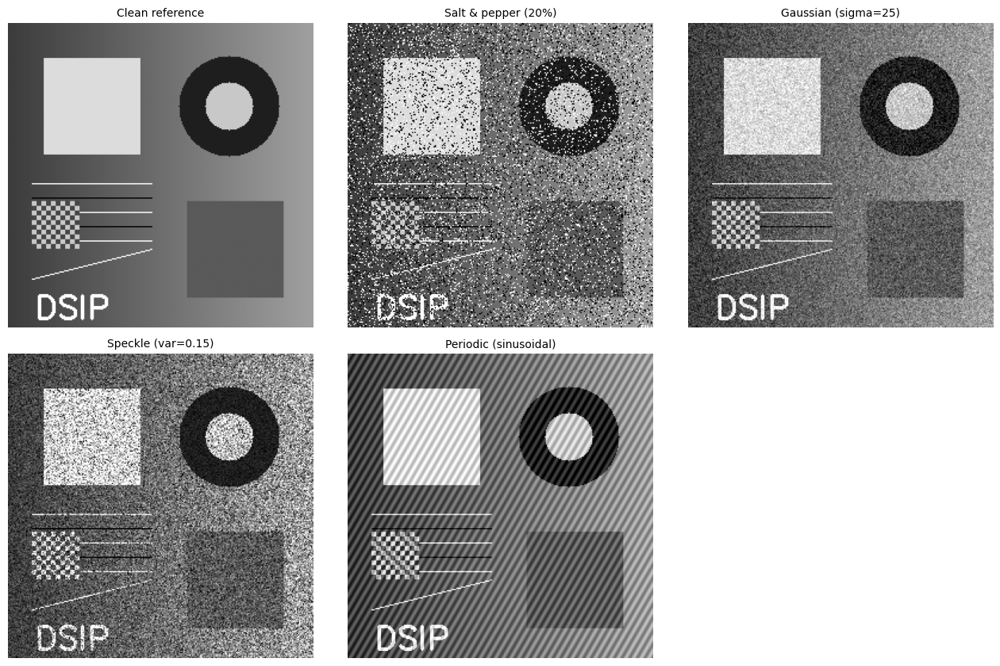

In [15]:
def make_reference(size=256):
    img = np.tile(np.linspace(60, 160, size, dtype=np.float32), (size, 1)).astype(np.uint8)
    cv2.rectangle(img, (30, 30), (110, 110), 220, -1)
    cv2.circle(img, (185, 70), 42, 30, -1)
    cv2.circle(img, (185, 70), 20, 200, -1)
    cv2.rectangle(img, (150, 150), (230, 230), 90, -1)
    for k in range(5):
        cv2.line(img, (20, 135 + 12 * k), (120, 135 + 12 * k), 255 if k % 2 == 0 else 0, 1)
    cv2.line(img, (20, 215), (120, 190), 255, 1)
    cv2.putText(img, "DSIP", (22, 248), cv2.FONT_HERSHEY_SIMPLEX, 0.9, 255, 2)
    yy, xx = np.mgrid[0:40, 0:40]
    img[150:190, 20:60] = np.where(((yy // 4 + xx // 4) % 2) == 0, 200, 70)
    return img

def add_salt_pepper(img, density, seed=0):
    rng = np.random.default_rng(seed)
    out = img.copy()
    r = rng.random(img.shape)
    out[r < density / 2] = 0
    out[(r >= density / 2) & (r < density)] = 255
    return out

def add_gaussian(img, sigma, seed=0):
    rng = np.random.default_rng(seed)
    return np.clip(img + rng.normal(0, sigma, img.shape), 0, 255).astype(np.uint8)

def add_speckle(img, var, seed=0):
    rng = np.random.default_rng(seed)
    f = img.astype(np.float64)
    return np.clip(f + f * rng.normal(0, np.sqrt(var), img.shape), 0, 255).astype(np.uint8)

def add_periodic(img, amp=40, freq=0.18, angle=30):
    h, w = img.shape
    yy, xx = np.mgrid[0:h, 0:w]
    t = np.deg2rad(angle)
    wave = amp * np.sin(2 * np.pi * freq * (xx * np.cos(t) + yy * np.sin(t)))
    return np.clip(img + wave, 0, 255).astype(np.uint8)

ref = make_reference()
show_grid([ref, add_salt_pepper(ref, 0.2), add_gaussian(ref, 25), add_speckle(ref, 0.15), add_periodic(ref)],
          ["Clean reference", "Salt & pepper (20%)", "Gaussian (sigma=25)", "Speckle (var=0.15)", "Periodic (sinusoidal)"],
          2, 3, (13, 8.5))

PSNR (dB) of the median filter - salt & pepper density vs window size
  Density     3x3     5x5     7x7     9x9   11x11    best
       5%   25.20   24.14   20.96   20.35   20.59     3x3
      10%   24.58   23.62   20.60   20.16   20.47     3x3
      20%   22.75   22.81   20.32   19.91   20.00     5x5
      30%   20.57   22.04   20.16   19.71   19.83     5x5
      40%   17.47   21.06   19.93   19.46   19.59     5x5
      50%   14.44   19.79   19.60   19.30   19.37     5x5
      60%   11.94   17.12   18.98   19.05   19.17   11x11


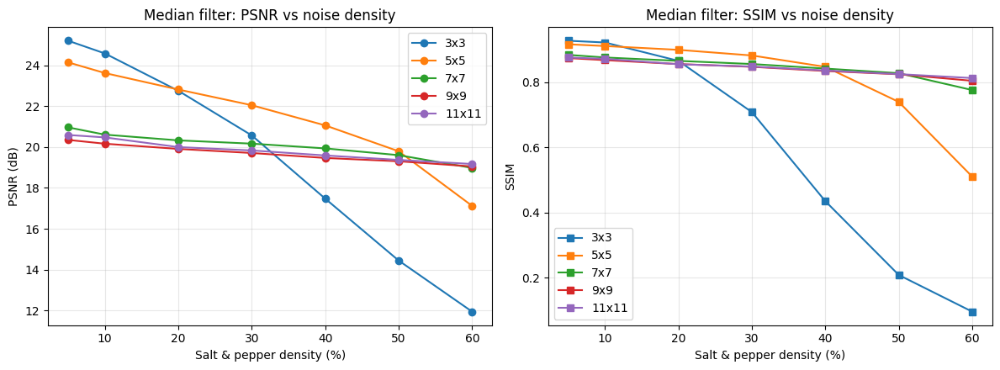

In [16]:
densities = [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
wsizes = [3, 5, 7, 9, 11]

psnr_tab = np.zeros((len(densities), len(wsizes)))
ssim_tab = np.zeros_like(psnr_tab)
for i, d in enumerate(densities):
    noisy = add_salt_pepper(ref, d)
    for j, k in enumerate(wsizes):
        f = median_filter(noisy, k)
        psnr_tab[i, j], ssim_tab[i, j] = psnr(ref, f), ssim(ref, f)

print("PSNR (dB) of the median filter - salt & pepper density vs window size")
print(f"{'Density':>9s}" + "".join(f"{str(k) + 'x' + str(k):>8s}" for k in wsizes) + f"{'best':>8s}")
for i, d in enumerate(densities):
    best = wsizes[int(np.argmax(psnr_tab[i]))]
    print(f"{d*100:8.0f}%" + "".join(f"{v:8.2f}" for v in psnr_tab[i]) + f"{str(best) + 'x' + str(best):>8s}")

plt.figure(figsize=(12, 4.5))
plt.subplot(1, 2, 1)
for j, k in enumerate(wsizes):
    plt.plot([d * 100 for d in densities], psnr_tab[:, j], marker="o", label=f"{k}x{k}")
plt.xlabel("Salt & pepper density (%)")
plt.ylabel("PSNR (dB)")
plt.title("Median filter: PSNR vs noise density")
plt.grid(alpha=0.3)
plt.legend()
plt.subplot(1, 2, 2)
for j, k in enumerate(wsizes):
    plt.plot([d * 100 for d in densities], ssim_tab[:, j], marker="s", label=f"{k}x{k}")
plt.xlabel("Salt & pepper density (%)")
plt.ylabel("SSIM")
plt.title("Median filter: SSIM vs noise density")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Salt & pepper density = 10%
Method                        PSNR (dB)     SSIM     EPI
Noisy input                       15.23    0.182   0.233
Mean 3x3 (linear)                 21.32    0.390  -0.019
Median 3x3                        24.58    0.921   0.490
Alpha-trimmed 5x5 (d=12)          23.19    0.886   0.153
Adaptive median (Smax=9)          21.27    0.891   0.357
Switching median 3x3              24.40    0.874   0.473
Morph open-close 3x3              21.47    0.864   0.449
Min 3x3                           10.08    0.074  -0.041
Max 3x3                            8.66    0.078  -0.048
Midpoint 3x3                      13.59    0.082  -0.063

Salt & pepper density = 30%
Method                        PSNR (dB)     SSIM     EPI
Noisy input                       10.56    0.082   0.117
Mean 3x3 (linear)                 17.65    0.199  -0.018
Median 5x5                        22.04    0.882   0.194
Alpha-trimmed 5x5 (d=12)          22.11    0.698   0.068
Adaptive median (Smax=9)       

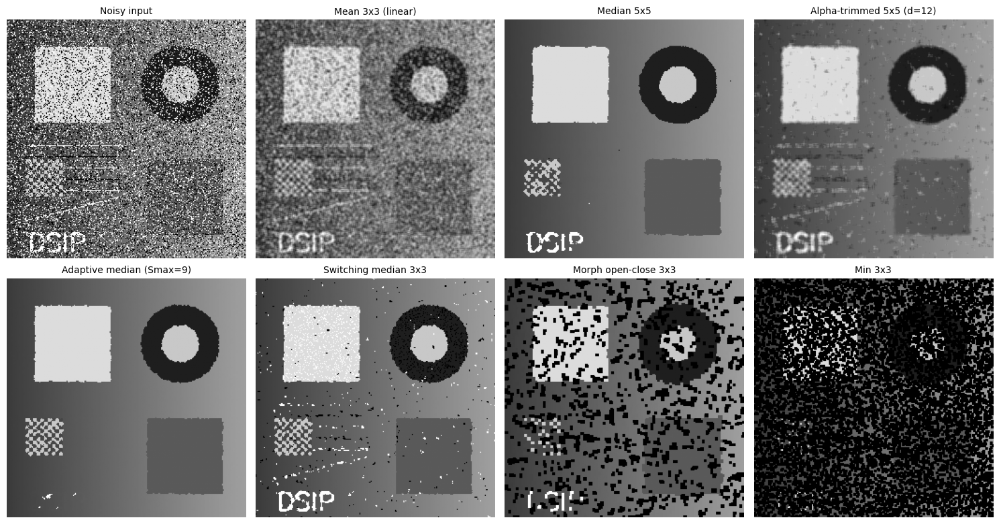

In [17]:
def compare_methods(noisy, k_med):
    return {
        "Noisy input": noisy,
        "Mean 3x3 (linear)": mean_filter(noisy, 3),
        f"Median {k_med}x{k_med}": median_filter(noisy, k_med),
        "Alpha-trimmed 5x5 (d=12)": alpha_trimmed_mean(noisy, 5, 12),
        "Adaptive median (Smax=9)": adaptive_median(noisy, 9),
        "Switching median 3x3": switching_median(noisy, 3),
        "Morph open-close 3x3": morph_open_close(noisy, 3),
        "Min 3x3": min_filter(noisy, 3),
        "Max 3x3": max_filter(noisy, 3),
        "Midpoint 3x3": midpoint_filter(noisy, 3),
    }

for d, kmed in ((0.10, 3), (0.30, 5)):
    noisy = add_salt_pepper(ref, d)
    res = compare_methods(noisy, kmed)
    print(f"Salt & pepper density = {d*100:.0f}%")
    print(f"{'Method':28s}{'PSNR (dB)':>11s}{'SSIM':>9s}{'EPI':>8s}")
    for name, im in res.items():
        print(f"{name:28s}{psnr(ref, im):11.2f}{ssim(ref, im):9.3f}{epi(ref, im):8.3f}")
    print()
    if d == 0.30:
        keys = ["Noisy input", "Mean 3x3 (linear)", f"Median {kmed}x{kmed}",
                "Alpha-trimmed 5x5 (d=12)", "Adaptive median (Smax=9)", "Switching median 3x3",
                "Morph open-close 3x3", "Min 3x3"]
        show_grid([res[k] for k in keys], keys, 2, 4, (15, 8))

Gaussian noise (sigma=25)
Method                        PSNR (dB)     SSIM     EPI
Noisy input                       20.33    0.252   0.424
Mean 3x3 (linear)                 23.40    0.574  -0.030
Median 3x3                        23.87    0.503   0.470
Median 5x5                        23.86    0.704   0.475
Alpha-trimmed 5x5 (d=4)           22.60    0.726   0.077
Alpha-trimmed 5x5 (d=12)          22.97    0.725   0.171
Midpoint 3x3                      21.35    0.450  -0.222

Speckle noise (var=0.15)
Method                        PSNR (dB)     SSIM     EPI
Noisy input                       15.23    0.182   0.223
Mean 3x3 (linear)                 21.13    0.403  -0.012
Median 3x3                        20.34    0.339   0.156
Median 5x5                        21.04    0.505   0.131
Alpha-trimmed 5x5 (d=4)           21.48    0.574   0.047
Alpha-trimmed 5x5 (d=12)          21.51    0.557   0.105
Midpoint 3x3                      18.66    0.303  -0.126



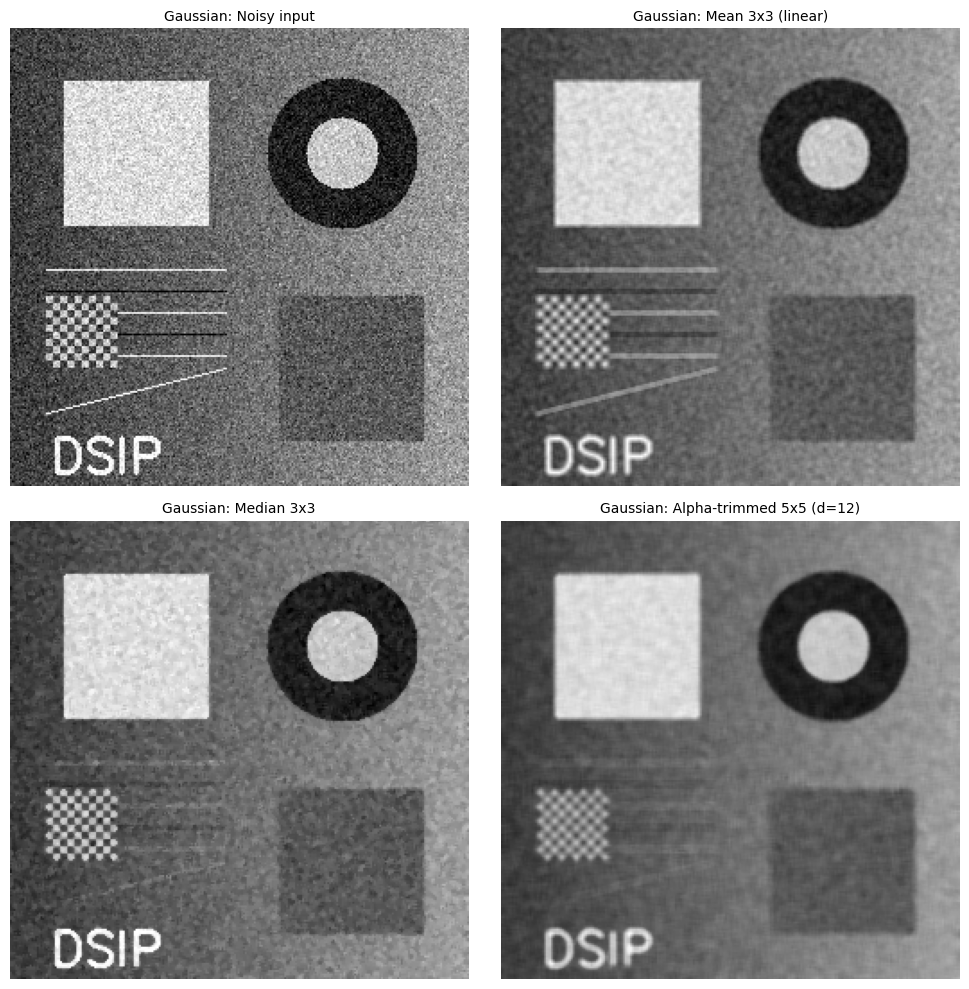

In [18]:
noisy_g = add_gaussian(ref, 25)
noisy_s = add_speckle(ref, 0.15)

def gs_methods(noisy):
    return {
        "Noisy input": noisy,
        "Mean 3x3 (linear)": mean_filter(noisy, 3),
        "Median 3x3": median_filter(noisy, 3),
        "Median 5x5": median_filter(noisy, 5),
        "Alpha-trimmed 5x5 (d=4)": alpha_trimmed_mean(noisy, 5, 4),
        "Alpha-trimmed 5x5 (d=12)": alpha_trimmed_mean(noisy, 5, 12),
        "Midpoint 3x3": midpoint_filter(noisy, 3),
    }

for nm, noisy in (("Gaussian noise (sigma=25)", noisy_g), ("Speckle noise (var=0.15)", noisy_s)):
    res = gs_methods(noisy)
    print(nm)
    print(f"{'Method':28s}{'PSNR (dB)':>11s}{'SSIM':>9s}{'EPI':>8s}")
    for name, im in res.items():
        print(f"{name:28s}{psnr(ref, im):11.2f}{ssim(ref, im):9.3f}{epi(ref, im):8.3f}")
    print()

keys = ["Noisy input", "Mean 3x3 (linear)", "Median 3x3", "Alpha-trimmed 5x5 (d=12)"]
show_grid([gs_methods(noisy_g)[k] for k in keys], ["Gaussian: " + k for k in keys], 2, 2, (10, 10))

Median filter, 20% salt & pepper: edge preservation vs window size
  Window  PSNR (dB)     EPI
     3x3      22.75   0.281
     5x5      22.81   0.300
     7x7      20.32   0.170
     9x9      19.91   0.149
   11x11      20.00   0.107
   15x15      19.67   0.071


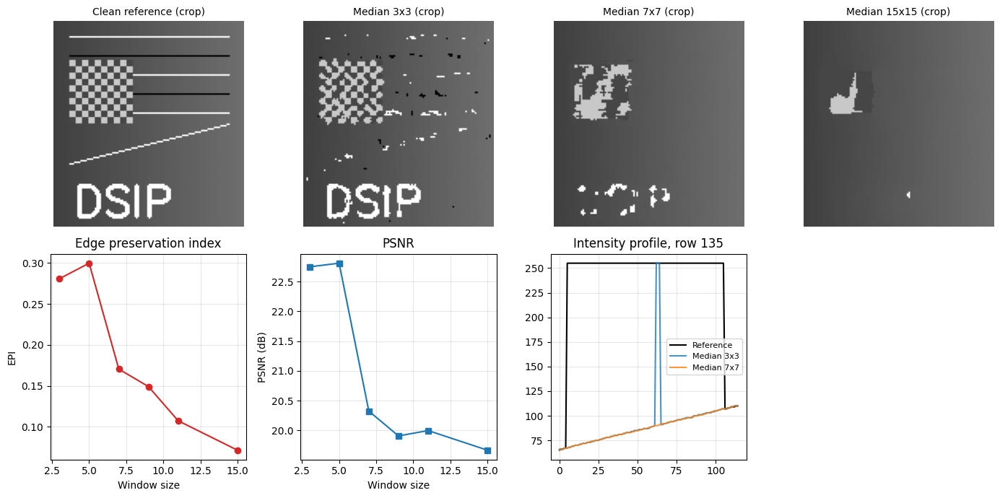

In [19]:
noisy = add_salt_pepper(ref, 0.20)
ks = [3, 5, 7, 9, 11, 15]
epis = [epi(ref, median_filter(noisy, k)) for k in ks]
psn = [psnr(ref, median_filter(noisy, k)) for k in ks]

print("Median filter, 20% salt & pepper: edge preservation vs window size")
print(f"{'Window':>8s}{'PSNR (dB)':>11s}{'EPI':>8s}")
for k, p, e in zip(ks, psn, epis):
    print(f"{str(k) + 'x' + str(k):>8s}{p:11.2f}{e:8.3f}")

crop = (slice(125, 255), slice(10, 130))
plt.figure(figsize=(14, 7))
panels = [("Clean reference", ref)] + [(f"Median {k}x{k}", median_filter(noisy, k)) for k in (3, 7, 15)]
for i, (lb, im) in enumerate(panels, 1):
    plt.subplot(2, 4, i)
    plt.imshow(im[crop], cmap="gray", vmin=0, vmax=255)
    plt.title(lb + " (crop)", fontsize=10)
    plt.axis("off")
plt.subplot(2, 4, 5)
plt.plot(ks, epis, marker="o", color="tab:red")
plt.xlabel("Window size")
plt.ylabel("EPI")
plt.title("Edge preservation index")
plt.grid(alpha=0.3)
plt.subplot(2, 4, 6)
plt.plot(ks, psn, marker="s", color="tab:blue")
plt.xlabel("Window size")
plt.ylabel("PSNR (dB)")
plt.title("PSNR")
plt.grid(alpha=0.3)
plt.subplot(2, 4, 7)
row = 135
plt.plot(ref[row, 15:130], label="Reference", color="k")
plt.plot(median_filter(noisy, 3)[row, 15:130], label="Median 3x3", alpha=0.8)
plt.plot(median_filter(noisy, 7)[row, 15:130], label="Median 7x7", alpha=0.8)
plt.title(f"Intensity profile, row {row}")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Step 7 - Failure cases

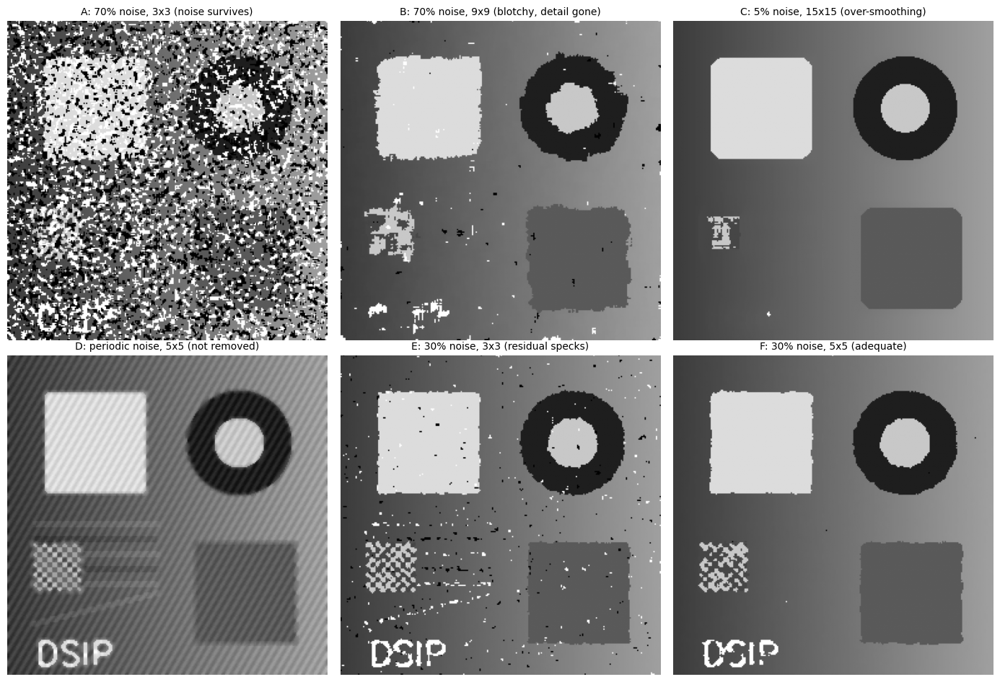

Case                                          PSNR (dB)     SSIM
A: 70% S&P, median 3x3                             9.71    0.051
B: 70% S&P, median 9x9                            18.16    0.729
C: 5% S&P, median 15x15                           20.04    0.859
D: periodic, median 5x5                           22.83    0.427
E: 30% S&P, median 3x3                            20.57    0.708
Periodic noisy input (no filter)                  19.20    0.223


In [20]:
case_a = median_filter(add_salt_pepper(ref, 0.70), 3)
case_b = median_filter(add_salt_pepper(ref, 0.70), 9)
case_c = median_filter(add_salt_pepper(ref, 0.05), 15)
per = add_periodic(ref)
case_d = median_filter(per, 5)
case_e = median_filter(add_salt_pepper(ref, 0.30), 3)

show_grid(
    [case_a, case_b, case_c, case_d, case_e, median_filter(add_salt_pepper(ref, 0.30), 5)],
    ["A: 70% noise, 3x3 (noise survives)", "B: 70% noise, 9x9 (blotchy, detail gone)",
     "C: 5% noise, 15x15 (over-smoothing)", "D: periodic noise, 5x5 (not removed)",
     "E: 30% noise, 3x3 (residual specks)", "F: 30% noise, 5x5 (adequate)"],
    2, 3, (14, 9.5))

print(f"{'Case':44s}{'PSNR (dB)':>11s}{'SSIM':>9s}")
cases = [("A: 70% S&P, median 3x3", case_a), ("B: 70% S&P, median 9x9", case_b),
         ("C: 5% S&P, median 15x15", case_c), ("D: periodic, median 5x5", case_d),
         ("E: 30% S&P, median 3x3", case_e)]
for nm, im in cases:
    r = per if "periodic" in nm else ref
    print(f"{nm:44s}{psnr(ref, im):11.2f}{ssim(ref, im):9.3f}")
print(f"{'Periodic noisy input (no filter)':44s}{psnr(ref, per):11.2f}{ssim(ref, per):9.3f}")

## Step 8 - Final results on the supplied images

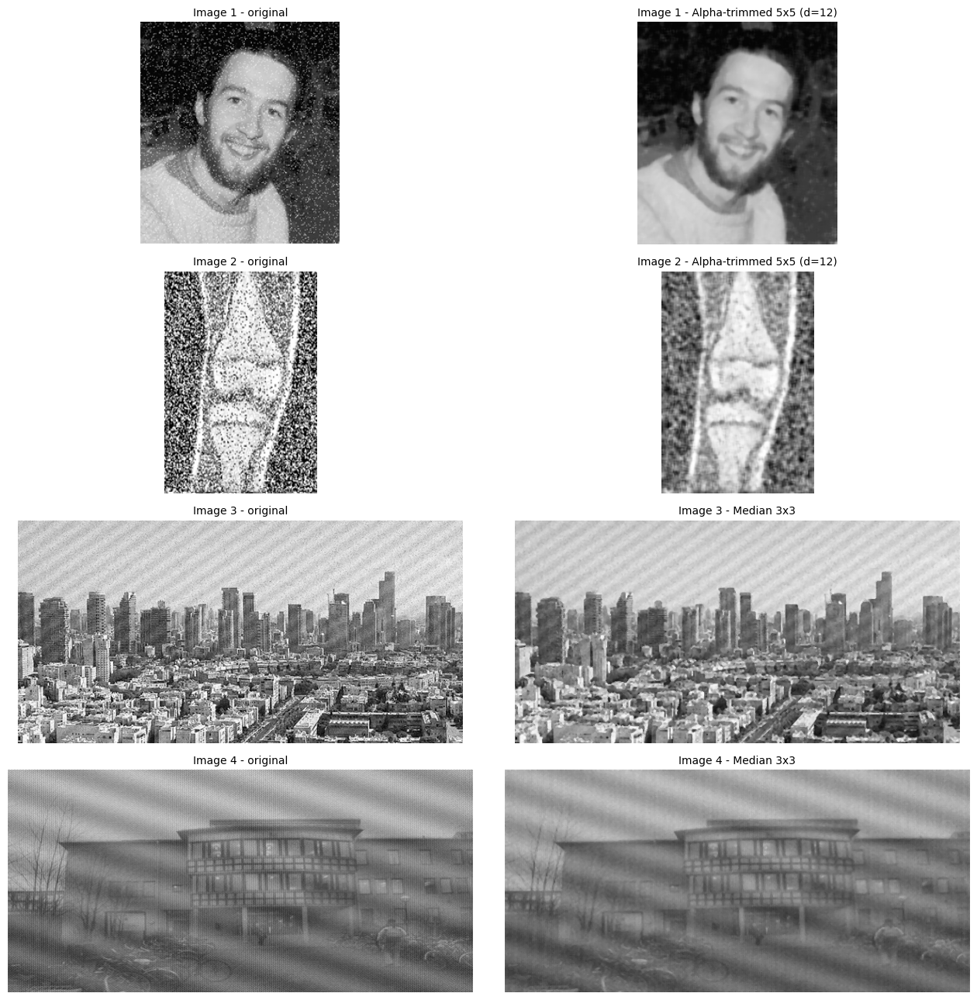

Image    Best non-linear filter            Outliers %       Noise sigma     Peak prominence
Image 1  Alpha-trimmed 5x5 (d=12)       4.45 ->  0.00    12.01 ->   0.55      2.59 ->  3.02
Image 2  Alpha-trimmed 5x5 (d=12)      19.23 ->  0.00    19.36 ->   1.28      1.65 ->  1.83
Image 3  Median 3x3                     4.14 ->  0.20    10.52 ->   3.90      3.01 ->  2.99
Image 4  Median 3x3                     0.00 ->  0.00     9.66 ->   1.66      5.55 ->  4.11


In [21]:
best = {
    "Image 1": ("Alpha-trimmed 5x5 (d=12)", alpha_trimmed_mean(gray1, 5, 12)),
    "Image 2": ("Alpha-trimmed 5x5 (d=12)", alpha_trimmed_mean(gray2, 5, 12)),
    "Image 3": ("Median 3x3", median_filter(gray3, 3)),
    "Image 4": ("Median 3x3", median_filter(gray4, 3)),
}
originals = {"Image 1": gray1, "Image 2": gray2, "Image 3": gray3, "Image 4": gray4}

plt.figure(figsize=(13, 13))
for r, (key, (nm, im)) in enumerate(best.items()):
    plt.subplot(4, 2, 2 * r + 1)
    plt.imshow(originals[key], cmap="gray", vmin=0, vmax=255)
    plt.title(key + " - original", fontsize=10)
    plt.axis("off")
    plt.subplot(4, 2, 2 * r + 2)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(key + " - " + nm, fontsize=10)
    plt.axis("off")
    cv2.imwrite(os.path.join(output_folder, key.replace(" ", "").lower() + "_best.png"), im)
plt.tight_layout()
plt.show()

print(f"{'Image':9s}{'Best non-linear filter':28s}{'Outliers %':>16s}{'Noise sigma':>18s}{'Peak prominence':>20s}")
for key, (nm, im) in best.items():
    o = originals[key]
    print(f"{key:9s}{nm:28s}{impulse_percent(o):7.2f} -> {impulse_percent(im):5.2f}"
          f"{noise_sigma(o):9.2f} -> {noise_sigma(im):6.2f}{peak_prominence(o):10.2f} -> {peak_prominence(im):5.2f}")